# 14. Canny edges

Canny edge map (0 / 255) with automatic thresholds. The weave itself also gives edges, so this mainly tests whether defect edges are stronger than weave edges. Binary map: the tile score becomes edge density after smoothing.

Method: `filters.py` (`METHOD_NAME = "canny"`). Evaluation: `evaluate.py`, same rules for every experiment (README section 7): threshold from `good_cal` only, false alarms on unseen `good_test` strips and on hard negatives, recall on defect tiles. Per-tile scores and the cal/test split are saved to `results/canny/`.

In [1]:
import sys, importlib

sys.path.insert(0, "../src/methods")
import filters as F    # all filters and methods
import evaluate as E   # shared evaluation (README section 7)
importlib.reload(F); importlib.reload(E)  # pick up edits without restarting the kernel

# ---- evaluation settings (same for every experiment) ----------------------
FABRIC = "02"           # fabric code = third part of the file name
METHOD_NAME = "canny"  # results go to results/<METHOD_NAME>/
THR_K = 4.0             # threshold = median + THR_K x 1.4826 x MAD of good_cal scores
MIN_AREA = 4            # damage mask: drop spots smaller than this (px); keep <= 4
SCORE_K = 25            # tile score = mean of the SCORE_K highest values of the smoothed map
SCORE_SIGMA = 2.0       # smoothing before scoring (px)
NORMALIZE = False       # this method gives a 0 / 255 map: its typical level is often 0, so no normalisation
SETTINGS = dict(thr_k=THR_K, min_area=MIN_AREA, score_k=SCORE_K, score_sigma=SCORE_SIGMA,
                normalize=NORMALIZE)

# ---- method settings -------------------------------------------------------
STEPS = F.DEFAULT_STEPS
SIGMA = 0.33              # automatic thresholds: (1 -/+ SIGMA) x median brightness


def method(tile):
    return F.canny(tile, STEPS, sigma=SIGMA)


fit = None

## Results for one fabric

In [2]:
res = E.evaluate(method, FABRIC, fit=fit, **SETTINGS)
assert res is not None, f"not enough tiles for fabric {FABRIC}"
S = E.summarize(res)
E.print_summary(res, S)
print("saved to", E.save_results(res, METHOD_NAME))

fabric 02: good_cal 140 tiles (10 strips), good_test 140 tiles (10 strips), 507 hard negatives, 38 defect tiles (0 background tiles skipped)
tile threshold 0.00   pixel threshold 0.00

                    predicted OK   predicted DAMAGED
good + hard neg.             647                   0
defect                        30                   8

false alarm rate    0.0% good_test, 0.0% hard negatives
recall              21.1%  (small <50 px: 0.0% of 23, large: 53.3% of 15)
strip level         false alarm 0.0% of 10 good strips, recall 21.1% of 38 defect strips
precision           100.0%
F1                  0.348
AUROC               0.605   (threshold-free ranking quality)
mean IoU            0.040 over all defect tiles, 0.188 over detected ones
time                1.3 ms/tile (median)
saved to C:\Users\chanupa.d\Documents\concord\fabric inspection\results\canny


### Score distribution and ROC curve
Left: tile scores with the threshold. Right: recall vs false alarm rate for every possible threshold; the dot is the threshold chosen from good_cal. The curve uses test tiles and is for analysis only.

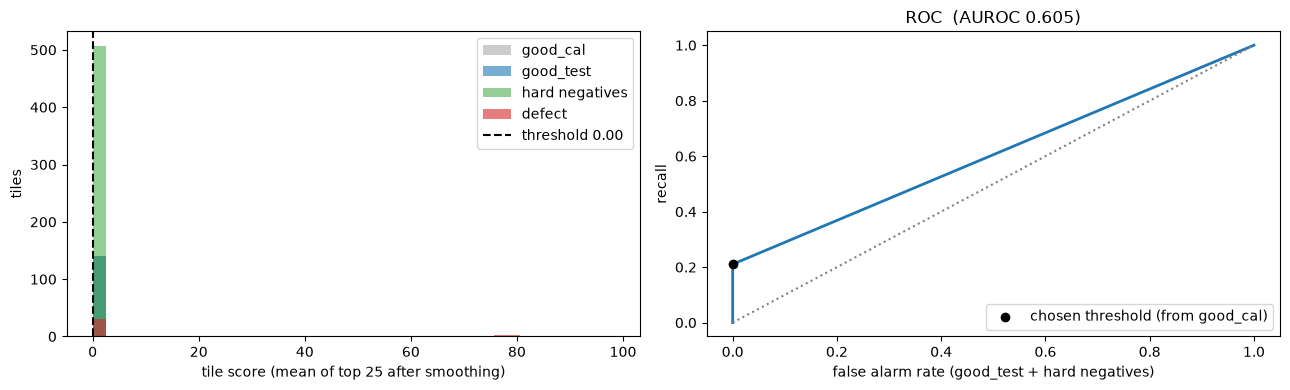

In [3]:
E.plot_scores_roc(res, S)

### Recall per defect type

In [4]:
E.print_by_type(res)

defect   tiles  found   recall  mean IoU  median area  median score
002          1      0       0%      0.00          151          0.00
006          7      7     100%      0.21         1260         78.96
019         23      0       0%      0.00           15          0.00
023          3      1      33%      0.02          778          0.00
030          4      0       0%      0.00           70          0.00


### Failure cases
Missed defects (lowest-scoring defect tiles) and false alarms (highest-scoring good_test / hard-negative tiles). Red = detected, green = ground-truth mask.

30 missed defects, 0 false alarms


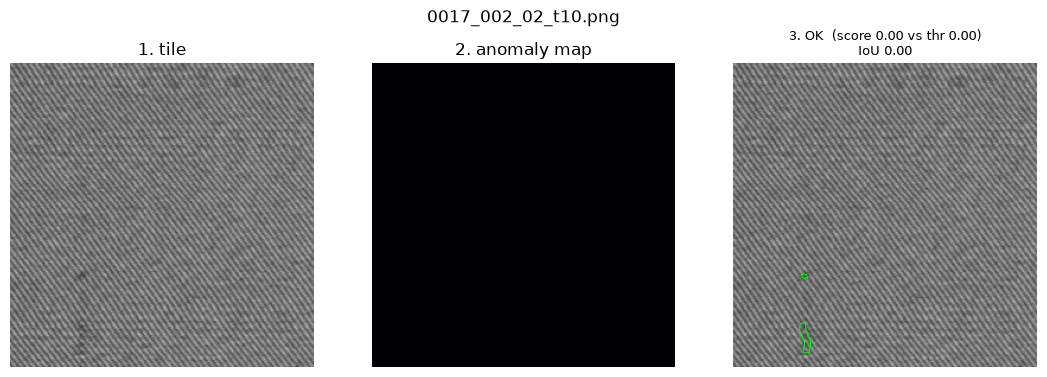

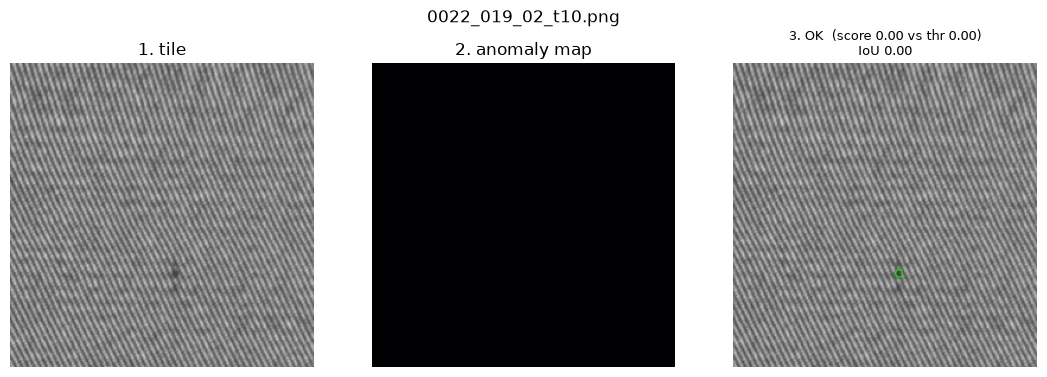

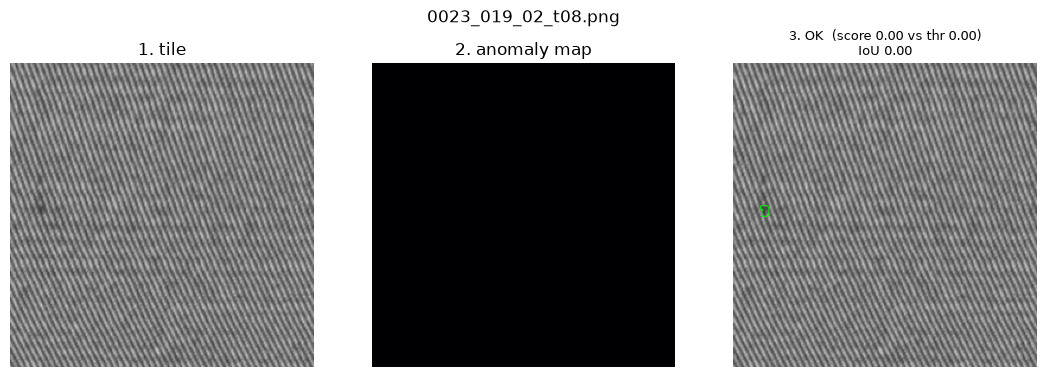

In [5]:
E.show_failures(res, n=3)

### Example tiles
Largest defect, smallest defect (by mask area) and the last good tile of `FABRIC`.

largest defect: 0016_006_02_t12.png, 2111 px


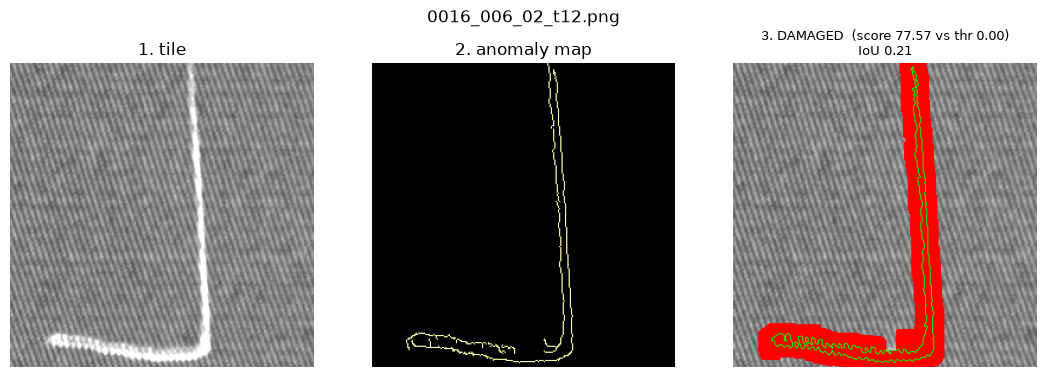

smallest defect: 0025_019_02_t10.png, 8 px


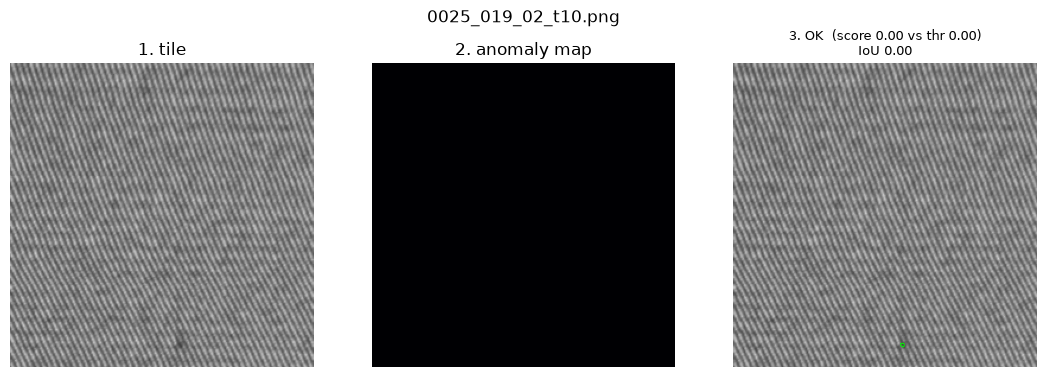

good tile: 0020_000_02_t15.png


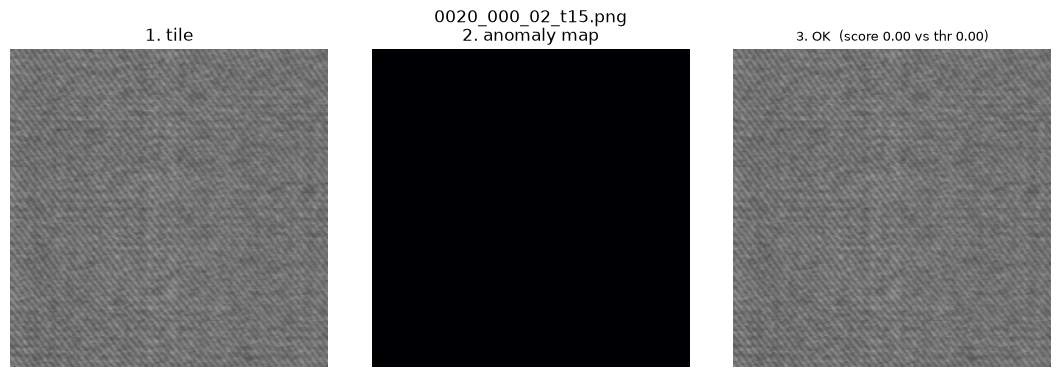

In [6]:
E.show_examples(res)

### One example per defect type
The dataset has 12 defect types (second part of the file name), spread over different fabrics. One tile per type: the clearest one (largest mask) from the fabric with the most tiles of that type. Each is judged with the threshold of its own fabric, set from that fabric's good_cal only (other fabrics are calibrated here, so this cell takes longer). Red = detected, green = ground-truth mask.

In [ ]:
E.show_per_type(method, fit, res, **SETTINGS)

## All fabrics
Same method and settings on every fabric, one threshold per fabric from its own good_cal strips. Columns: FAR on good_test and on hard negatives (hn), recall overall / small / large defects, strip-level FAR and recall, AUROC, IoU, ms per tile.

In [7]:
summaries = E.all_fabrics(method, fit, METHOD_NAME, **SETTINGS)

fabric   test  hard defect    FAR  FAR hn  recall  small  large stripFAR stripRec  AUROC   IoU    ms
----------------------------------------------------------------------------------------------------
00        110    76      9   0.0%    0.0%    0.0%   0.0%   0.0%     0.0%     0.0%  0.366  0.00   1.2
01        154   146     28   0.0%    2.7%   57.1%   0.0%  61.5%     0.0%    16.7%  0.777  0.03   1.4
02        140   507     38   0.0%    0.0%   21.1%   0.0%  53.3%     0.0%    21.1%  0.605  0.04   1.3
03        110   256     89   0.0%    0.0%    0.0%   0.0%   0.0%     0.0%     0.0%  0.550  0.00   1.9
04        138   129     12   2.2%    1.6%   16.7%   0.0%  28.6%    20.0%    20.0%  0.574  0.03   1.3
05        150    13      1   0.7%    0.0%    0.0%    n/a   0.0%    10.0%     0.0%  0.497  0.00   1.2
06        143    81      7   1.4%    3.7%   42.9%  20.0% 100.0%    20.0%    50.0%  0.707  0.00   1.3
-------------------------------------------------------------------------------------------